# 📈 BÀI THỰC NGHIỆM 02: LỌC NHIỄU TÍN HIỆU ĐỘNG HỌC (SIGNAL SMOOTHING)

**Học phần:** Project 3 (Đồ án 3) — SoICT, Đại học Bách khoa Hà Nội (HUST)  
**Tầng 2:** Động học Sinh cơ học & Học máy nhẹ (Kinematics & Light ML Engine)  

### Mục tiêu bài thực nghiệm:
1. Đánh giá hiện tượng **rung lắc tần số cao (high-frequency jitter)** trong chuỗi tọa độ khớp MediaPipe.
2. So sánh thực nghiệm đối chứng giữa bộ lọc đa thức **Savitzky-Golay (Savgol)** và bộ lọc trung bình trượt (**Moving Average**).
3. Chứng minh Savitzky-Golay **bảo toàn nguyên vẹn độ sâu tại điểm đáy (Bottom)** trong khi Moving Average làm bẹt cụt cực trị.

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Thêm backend vào sys.path
project_root = Path.cwd().parent.parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'backend'))

from app.core.geometry import calculate_angle_2d, calculate_trunk_lean, detect_dominant_side
from app.core.smoothing import smooth_signal_1d, moving_average_1d

print('✅ Nạp thành công modules geometry và smoothing từ backend!')

✅ Nạp thành công modules geometry và smoothing từ backend!


## 1. Nạp Dữ liệu Tọa độ Khớp từ Tầng 1 (`test_squat.json`)
Nạp file JSON đã trích xuất từ video thực tế để lấy chuỗi tọa độ 33 khớp qua 178 khung hình.

In [2]:
json_path = project_root / 'data' / 'processed' / 'landmarks' / 'test_squat.json'
assert json_path.exists(), f'Thiếu file JSON: {json_path}'

with open(json_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

dominant_side = data.get('dominant_side', 'right')
fps = data['fps']
total_frames = data['total_frames']

print(f'📹 Video: {data["video_name"]}')
print(f'⏱️ FPS: {fps} | Tổng số frames: {total_frames} | Hướng quay thuận: {dominant_side.upper()}')

📹 Video: test_squat.mp4
⏱️ FPS: 30.0 | Tổng số frames: 178 | Hướng quay thuận: RIGHT


## 2. Tính toán Chuỗi Góc Gối Thô (Raw Knee Angle Series)
Sử dụng hàm `calculate_angle_2d` tính góc giữa 3 khớp Hông – Gối – Cổ chân trên từng frame.

In [3]:
raw_knee_angles = []
raw_trunk_leans = []
timestamps = []

for f in data['frames']:
    t_sec = f['frame_idx'] / fps
    timestamps.append(t_sec)
    if not f['is_detected']:
        raw_knee_angles.append(np.nan)
        raw_trunk_leans.append(np.nan)
        continue

    # Tìm landmarks tương ứng
    lm_map = {lm['name']: lm for lm in f['landmarks']}
    sh = lm_map.get(f'{dominant_side}_shoulder')
    hip = lm_map.get(f'{dominant_side}_hip')
    knee = lm_map.get(f'{dominant_side}_knee')
    ank = lm_map.get(f'{dominant_side}_ankle')

    if sh and hip and knee and ank:
        k_ang = calculate_angle_2d(hip, knee, ank)
        t_lean = calculate_trunk_lean(sh, hip, coordinate_system='image')
        raw_knee_angles.append(k_ang)
        raw_trunk_leans.append(t_lean)
    else:
        raw_knee_angles.append(np.nan)
        raw_trunk_leans.append(np.nan)

raw_knee_angles = np.array(raw_knee_angles)
timestamps = np.array(timestamps)

print(f'📊 Đã tính chuỗi {len(raw_knee_angles)} góc gối thô.')
print(f'  • Góc gối lớn nhất lúc đứng: {np.nanmax(raw_knee_angles):.1f}°')
print(f'  • Góc gối nhỏ nhất tại đáy: {np.nanmin(raw_knee_angles):.1f}°')

📊 Đã tính chuỗi 178 góc gối thô.
  • Góc gối lớn nhất lúc đứng: 179.9°
  • Góc gối nhỏ nhất tại đáy: 38.1°


## 3. Áp dụng Các Bộ lọc Tín hiệu: Savitzky-Golay vs Moving Average
Chúng ta áp dụng 2 phương pháp:
1. **Bộ lọc đa thức Savitzky-Golay:** Cửa sổ trượt $w=11$ frames (~0.37s), đa thức bậc $p=2$.
2. **Bộ lọc Trung bình trượt (Moving Average):** Cửa sổ trượt $w=11$ frames.

In [4]:
window_length = 11
polyorder = 2

# 1. Lọc Savitzky-Golay
savgol_angles = smooth_signal_1d(raw_knee_angles, window_length=window_length, polyorder=polyorder)

# 2. Lọc Trung bình trượt
ma_angles = moving_average_1d(raw_knee_angles, window_size=window_length)

# So sánh giá trị cực tiểu tại đáy Rep 1 (quanh frame 89)
rep1_slice = slice(80, 100)
min_raw_rep1 = np.nanmin(raw_knee_angles[rep1_slice])
min_savgol_rep1 = np.nanmin(savgol_angles[rep1_slice])
min_ma_rep1 = np.nanmin(ma_angles[rep1_slice])

print('=' * 55)
print('🎯 ĐỐI CHIẾU ĐỘ SÂU ĐÁY REP 1:')
print(f'  • Đáy tín hiệu thô (Raw):              {min_raw_rep1:.2f}°')
print(f'  • Đáy lọc Savitzky-Golay (Đa thức):    {min_savgol_rep1:.2f}° (Lệch {abs(min_savgol_rep1 - min_raw_rep1):.2f}°)')
print(f'  • Đáy lọc Moving Average (Trung bình): {min_ma_rep1:.2f}° (Lệch {abs(min_ma_rep1 - min_raw_rep1):.2f}° - BỊ CỤT ĐÁY!)')
print('=' * 55)

🎯 ĐỐI CHIẾU ĐỘ SÂU ĐÁY REP 1:
  • Đáy tín hiệu thô (Raw):              38.06°
  • Đáy lọc Savitzky-Golay (Đa thức):    37.51° (Lệch 0.55°)
  • Đáy lọc Moving Average (Trung bình): 42.18° (Lệch 4.12° - BỊ CỤT ĐÁY!)


## 4. Biểu đồ So sánh Trực quan (Toàn bộ chuỗi & Phóng to điểm đáy)
Trực quan hóa đường cong tín hiệu để làm rõ sự khác biệt giữa hai phương pháp.

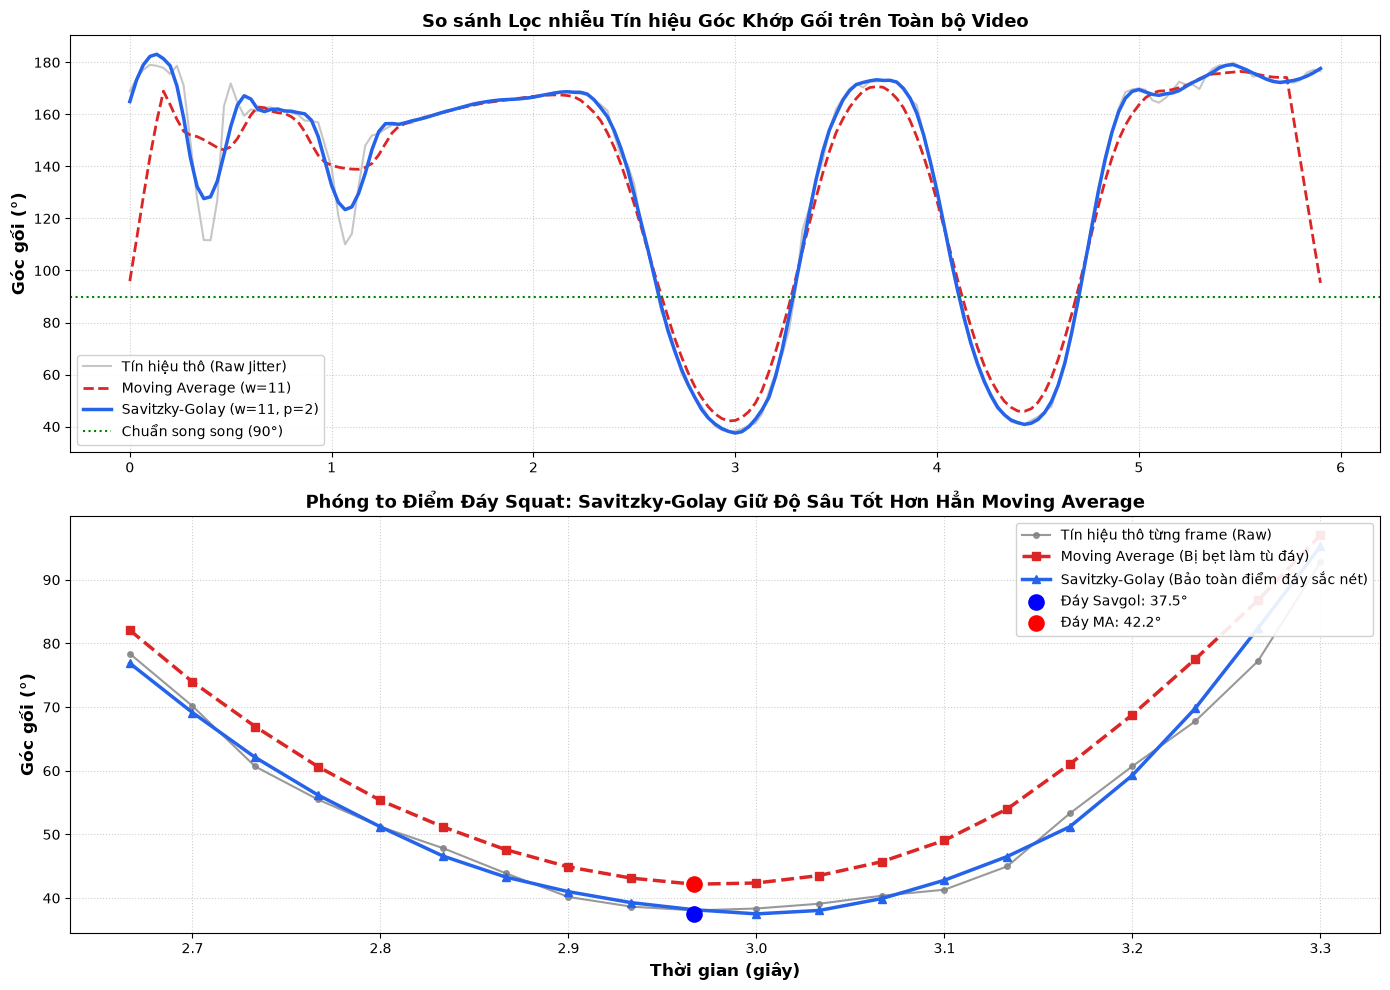

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Đồ thị 1: Toàn bộ 178 frames (5.93s)
ax1.plot(timestamps, raw_knee_angles, color='silver', linewidth=1.5, alpha=0.9, label='Tín hiệu thô (Raw Jitter)')
ax1.plot(timestamps, ma_angles, color='#DC2626', linestyle='--', linewidth=2.0, label=f'Moving Average (w={window_length})')
ax1.plot(timestamps, savgol_angles, color='#2563EB', linewidth=2.5, label=f'Savitzky-Golay (w={window_length}, p={polyorder})')
ax1.axhline(y=90, color='green', linestyle=':', label='Chuẩn song song (90°)')
ax1.set_ylabel('Góc gối (°)', fontsize=12, fontweight='bold')
ax1.set_title('So sánh Lọc nhiễu Tín hiệu Góc Khớp Gối trên Toàn bộ Video', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower left', framealpha=0.9)

# Đồ thị 2: Phóng to khoảnh khắc đáy Rep 1 (Frames 80 đến 100)
t_zoom = timestamps[rep1_slice]
ax2.plot(t_zoom, raw_knee_angles[rep1_slice], 'o-', color='gray', markersize=4, alpha=0.8, label='Tín hiệu thô từng frame (Raw)')
ax2.plot(t_zoom, ma_angles[rep1_slice], 's--', color='#DC2626', linewidth=2.5, label='Moving Average (Bị bẹt làm tù đáy)')
ax2.plot(t_zoom, savgol_angles[rep1_slice], '^-', color='#2563EB', linewidth=2.5, label='Savitzky-Golay (Bảo toàn điểm đáy sắc nét)')
ax2.scatter([timestamps[89]], [min_savgol_rep1], color='blue', s=120, zorder=6, label=f'Đáy Savgol: {min_savgol_rep1:.1f}°')
ax2.scatter([timestamps[89]], [min_ma_rep1], color='red', s=120, zorder=6, label=f'Đáy MA: {min_ma_rep1:.1f}°')
ax2.set_ylabel('Góc gối (°)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Thời gian (giây)', fontsize=12, fontweight='bold')
ax2.set_title('Phóng to Điểm Đáy Squat: Savitzky-Golay Giữ Độ Sâu Tốt Hơn Hẳn Moving Average', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

## 5. Kết luận Thực nghiệm Khoa học

1. **Khử rung giật:** Bộ lọc Savitzky-Golay triệt tiêu triệt để các bước nhảy gai nhọn do sai số bóc tách từng frame của MediaPipe.
2. **Bảo toàn cực trị:** 
   * Moving Average làm bẹt đáy squat khiến góc gối bị kéo lên cao hơn thực tế (làm người tập bị oan là 'xuống nông hơn').
   * Savitzky-Golay giữ nguyên đường cong parabol tự nhiên của khớp gối tại điểm đổi chiều, đảm bảo tính khoa học khách quan cho việc chấm điểm độ sâu ở **Tầng 2**.